# FactIndic 06 – Evaluation, hypothesis tests, code-mixing analysis, figures

Computes ROUGE-1/2/L (P/R/F1, Unicode tokenizer), METEOR, BERTScore (P/R/F1), LaBSE similarity, average summary length, compression ratio and inference time; merges the factuality scores; tests **H1** (code-mixed vs monolingual input, paired Wilcoxon/McNemar with bootstrap CIs, Holm correction) and **H2** (Track B/BV vs A, and whether they shrink the gap: difference-in-differences); analyses factuality by Code-Mixing Index, tokenizer fertility, script of the output and error types; draws the figures; and writes the blind human-evaluation sheets.

| Setting (right-hand panel) | Value |
|---|---|
| Accelerator | **GPU T4** |
| Internet | **On** |
| Inputs to attach | output of notebook 05 |
| Time (full profile) | 15–30 min |

Run it with **Save Version → Save & Run All (Commit)**. When it finishes, its output (folder `factindic_out`) is
ready to attach to the next notebook. Each notebook's output contains every earlier stage, so you only ever attach
the previous notebook.

In [1]:
# ── Setup: make the factindic code importable ─────────────────────────────────────────
# Kaggle: upload factindic-code.zip as a private dataset and attach it
#         (right-hand panel -> Add Input -> Your Work / Datasets -> factindic-code -> "+").
# Colab:  put factindic-code.zip in My Drive (and run the Google Drive cell first), or upload it to /content.
# Or:     push the repository to GitHub and paste its URL here (needs Internet).
REPO_URL = ""   # e.g. "https://github.com/<your-username>/factindic"

import glob, os, shutil, subprocess, sys, zipfile

ON_COLAB = "google.colab" in sys.modules
SRC = "/content/factindic_src" if ON_COLAB else "/kaggle/working/factindic_src"

def _is_pkg(d):
    return all(os.path.exists(os.path.join(d, f)) for f in ("__init__.py", "pipeline.py", "config.py"))

def _candidates():
    inits = glob.glob("/kaggle/input/**/__init__.py", recursive=True)
    zips = glob.glob("/kaggle/input/**/*.zip", recursive=True)
    if ON_COLAB:  # shallow search only: Google Drive can be huge
        for base in ("/content", "/content/drive/MyDrive"):
            for depth in ("", "*/", "*/*/"):
                inits += glob.glob(f"{base}/{depth}factindic/__init__.py")
            zips += [z for z in glob.glob(f"{base}/*.zip") + glob.glob(f"{base}/*/*.zip")
                     if "factindic" in os.path.basename(z).lower()]
    return sorted(set(inits)), sorted(set(zips))

def _unzip(z):
    try:
        with zipfile.ZipFile(z) as zf:
            hits = [n for n in zf.namelist() if n.endswith("factindic/__init__.py")]
            if hits:
                shutil.rmtree(SRC, ignore_errors=True)
                zf.extractall(SRC)
                return os.path.dirname(os.path.dirname(os.path.join(SRC, sorted(hits, key=len)[-1])))
    except zipfile.BadZipFile:
        pass
    return None

def _find_code():
    inits, zips = _candidates()
    # 0) Colab: always unpack the newest zip from Drive, so replacing the zip there updates the code
    if ON_COLAB:
        for z in sorted(zips, key=os.path.getmtime, reverse=True):
            code = _unzip(z)
            if code:
                print("using", z)
                return code
    # 1) the repository folder (…/factindic/factindic/__init__.py)
    for p in inits:
        d = os.path.dirname(p)
        if _is_pkg(d) and os.path.basename(d) == "factindic":
            return os.path.dirname(d)
    # 2) only the inner package was uploaded (files directly in the dataset): copy it under the right name
    for p in inits:
        d = os.path.dirname(p)
        if _is_pkg(d):
            shutil.copytree(d, os.path.join(SRC, "factindic"), dirs_exist_ok=True)
            for req in glob.glob(os.path.join(os.path.dirname(d), "**", "requirements.txt"), recursive=True)[:1]:
                shutil.copy(req, SRC)
            return SRC
    # 3) a zip that nobody unpacked
    for z in zips:
        code = _unzip(z)
        if code:
            return code
    # 4) running locally from the repository
    for p in ("factindic", "../factindic"):
        if _is_pkg(p):
            return os.path.abspath(os.path.dirname(p) or ".")
    return None

CODE = _find_code()
if CODE is None and REPO_URL:
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, SRC], check=True)
    CODE = SRC
if CODE is None:
    where = (sorted(glob.glob("/content/*")) + sorted(glob.glob("/content/drive/MyDrive/*"))[:30]) if ON_COLAB else \
            (sorted(glob.glob("/kaggle/input/*")) + sorted(glob.glob("/kaggle/input/*/*"))[:30])
    how = ("Put factindic-code.zip in My Drive and run the Google Drive cell first (or upload the zip to /content)."
           if ON_COLAB else
           "Attach the dataset: right-hand panel -> Add Input -> Your Work (or Datasets) -> factindic-code -> '+'. "
           "If you uploaded it a minute ago, wait until Kaggle finishes processing it.")
    raise FileNotFoundError("factindic code not found.\n" + how + "\nWhat this notebook can see:\n  "
                            + ("\n  ".join(where) if where else "(nothing)"))
sys.path.insert(0, CODE)
os.environ["PYTHONPATH"] = CODE + os.pathsep + os.environ.get("PYTHONPATH", "")
req = os.path.join(CODE, "requirements.txt")
pkgs = ["-r", req] if os.path.exists(req) else ["indic-transliteration", "wordfreq", "datasketch", "bert-score",
                                                "python-docx", "feedparser", "trafilatura", "peft", "openpyxl",
                                                "bitsandbytes"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
import factindic
from factindic import Config
from factindic import pipeline as P
print("factindic", factindic.__version__, "loaded from", CODE)

factindic 1.0.0 loaded from /kaggle/input/datasets/lkr1196/factindic-code/factindic


In [2]:
# ── Configuration ────────────────────────────────────────────────────────────────────
# Use the SAME profile in every notebook of the chain.
#   "full"  – the real experiment
#   "quick" – ~25 articles per language, to check the whole chain on Kaggle first
#   "mock"  – CPU dry run with stand-in models (no GPU, no downloads); never report its numbers
PROFILE = "full"
cfg = Config.make(PROFILE)
print(cfg.to_json())

{
  "profile": "full",
  "seed": 13,
  "langs": [
    "hi",
    "bn"
  ],
  "variants": [
    "mono",
    "cm",
    "roman"
  ],
  "data_source": "xlsum",
  "n_test": 200,
  "n_dev": 30,
  "n_train_cm": 60,
  "min_words": 120,
  "max_words_raw": 1200,
  "lead_words": 300,
  "max_sents": 14,
  "min_summary_words": 8,
  "max_summary_words": 60,
  "near_dup_threshold": 0.8,
  "natural_split": [
    0.7,
    0.1,
    0.2
  ],
  "scrape": true,
  "n_natural_per_lang": 100,
  "backend": "auto",
  "summarizer_model": "Qwen/Qwen3-4B-Instruct-2507",
  "codemix_model": "Qwen/Qwen3-4B-Instruct-2507",
  "openai_base_url": "",
  "openai_model": "",
  "openai_concurrency": 4,
  "max_model_len": 6144,
  "max_batch_tokens": 24000,
  "max_batch_size": 24,
  "repetition_penalty": 1.0,
  "workers": -1,
  "quantize": "auto",
  "summary_max_words": 40,
  "tracks": [
    "A",
    "B",
    "BV"
  ],
  "max_new_tokens_A": 448,
  "max_new_tokens_B": 1536,
  "seq2seq_models": [
    "mt5",
    "indicbart"
  ],
 

Optional: the official XL-Sum ROUGE scorer (language-specific stemming) so your ROUGE is comparable with published XL-Sum numbers. If it does not install, the notebook reports the Unicode ROUGE only.

In [3]:
INSTALL_XLSUM_ROUGE = True
if INSTALL_XLSUM_ROUGE and PROFILE != "mock":
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyonmttok",
                    "git+https://github.com/csebuetnlp/xl-sum.git#subdirectory=multilingual_rouge_scoring"], check=False)

ERROR: Could not find a version that satisfies the requirement pyonmttok (from versions: none)
ERROR: No matching distribution found for pyonmttok


In [4]:
res = P.run_stage06(cfg)

Stages available: 01_data, 02_codemix, 03_seq2seq, 04_llm, 05_verify
ROUGE / METEOR / lengths
  (official XL-Sum ROUGE scorer not installed; only the Unicode ROUGE is reported)
BERTScore / LaBSE


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

... (33 outputs left out)

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (546 > 512). Running this sequence through the model will result in indexing errors


Figures
Human-evaluation sheets
  1057 sentences to annotate in /kaggle/working/factindic_out/06_evaluate/human_eval
# Key findings (auto-generated)

All differences are paired over the same test articles; 95% bootstrap CIs; p-values Holm-corrected.

## H1 - does code-mixed input reduce factual consistency?
- bn IndicBART-XLSum, NLI support: 68.3 (mono) -> 69.4 (cm), Δ = +1.1 [-2.3, +4.4], p_holm = 1 (not significant).
- bn IndicBART-XLSum, NLI support: 68.3 (mono) -> 63.1 (roman), Δ = -5.3 [-9.5, -1.2], p_holm = 1 (not significant).
- bn IndicBART-XLSum, Any hallucination rate: 36.6 (mono) -> 54.2 (cm), Δ = +17.6 [+7.7, +28.2], p_holm = 0.196 (not significant).
- bn IndicBART-XLSum, Any hallucination rate: 36.6 (mono) -> 75.4 (roman), Δ = +38.7 [+28.2, +49.3], p_holm = 2.78e-07 (significant).
- bn mT5-XLSum, NLI support: 83.6 (mono) -> 84.9 (cm), Δ = +1.3 [-2.8, +5.4], p_holm = 1 (not significant).
- bn mT5-XLSum, NLI support: 83.6 (mono) -> 65.6 (roman), Δ = -18.0 [-23.4, -12.7], p_h

In [5]:
from IPython.display import Markdown, display
display(Markdown(open(f"{cfg.out_root}/06_evaluate/results.md", encoding="utf-8").read()))

# FactIndic results

Paired test articles only (n per cell in the `n` column). Mean ± half-width of the 95% bootstrap CI.

## Content / Meaning

| lang | system | track | variant | n | ROUGE-1 F1 | ROUGE-2 F1 | ROUGE-L F1 | ROUGE-L (XL-Sum scorer) | METEOR | BERTScore F1 | LaBSE sim. (ref) | Entity F1 (ref) | Numeral F1 (ref) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| bn | indicbart | - | mono | 142 | 8.0 ± 1.2 | 2.1 ± 0.7 | 6.5 ± 1.0 | – | 7.6 ± 1.4 | 59.2 ± 1.4 | 42.9 ± 2.2 | 19.7 ± 4.7 | 0.0 ± 0.0 |
| bn | indicbart | - | cm | 142 | 6.1 ± 1.2 | 1.5 ± 0.8 | 5.1 ± 1.0 | – | 5.6 ± 1.2 | 56.4 ± 1.5 | 41.8 ± 2.4 | 16.4 ± 4.4 | 10.0 ± 15.0 |
| bn | indicbart | - | roman | 142 | 0.0 ± 0.0 | 0.0 ± 0.0 | 0.0 ± 0.0 | – | 0.0 ± 0.0 | 50.5 ± 0.8 | 26.7 ± 2.1 | 10.6 ± 3.1 | 15.4 ± 16.7 |
| bn | mt5 | - | mono | 142 | 22.3 ± 2.4 | 8.9 ± 1.9 | 19.9 ± 2.2 | – | 15.7 ± 2.2 | 74.5 ± 0.9 | 63.9 ± 2.0 | 41.1 ± 6.0 | 30.0 ± 35.0 |
| bn | mt5 | - | cm | 142 | 19.1 ± 2.0 | 6.3 ± 1.5 | 16.9 ± 1.9 | – | 12.7 ± 1.9 | 73.2 ± 0.9 | 63.8 ± 2.0 | 39.5 ± 5.9 | 60.0 ± 40.0 |
| bn | mt5 | - | roman | 142 | 0.0 ± 0.1 | 0.0 ± 0.0 | 0.0 ± 0.1 | – | 0.0 ± 0.0 | 58.7 ± 0.5 | 33.5 ± 2.6 | 13.0 ± 3.8 | 23.3 ± 28.3 |
| bn | mt5-lora-cm | - | mono | 142 | 21.8 ± 2.5 | 8.7 ± 1.9 | 19.5 ± 2.3 | – | 15.3 ± 2.3 | 74.5 ± 0.9 | 63.6 ± 2.0 | 39.8 ± 5.9 | 25.0 ± 29.2 |
| bn | mt5-lora-cm | - | cm | 142 | 19.7 ± 1.9 | 6.5 ± 1.5 | 17.5 ± 1.7 | – | 13.0 ± 1.8 | 73.4 ± 0.9 | 63.5 ± 1.9 | 37.7 ± 6.0 | 48.0 ± 40.0 |
| bn | mt5-lora-cm | - | roman | 142 | 0.0 ± 0.0 | 0.0 ± 0.0 | 0.0 ± 0.0 | – | 0.0 ± 0.0 | 58.5 ± 0.6 | 32.4 ± 2.6 | 11.0 ± 3.7 | 20.0 ± 30.0 |
| bn | qwen3-4b-instruct-2507 | A | mono | 142 | 14.7 ± 1.7 | 3.6 ± 1.0 | 12.0 ± 1.4 | – | 10.5 ± 1.6 | 71.2 ± 0.7 | 56.3 ± 2.0 | 27.4 ± 5.2 | 10.7 ± 13.7 |
| bn | qwen3-4b-instruct-2507 | A | cm | 142 | 13.2 ± 1.6 | 2.6 ± 0.8 | 10.5 ± 1.3 | – | 9.2 ± 1.4 | 70.5 ± 0.6 | 55.6 ± 1.9 | 27.4 ± 4.9 | 14.5 ± 16.7 |
| bn | qwen3-4b-instruct-2507 | A | roman | 142 | 8.5 ± 1.1 | 1.0 ± 0.5 | 7.2 ± 1.0 | – | 5.2 ± 0.9 | 69.0 ± 0.5 | 49.9 ± 1.8 | 18.8 ± 4.4 | 11.7 ± 14.9 |
| bn | qwen3-4b-instruct-2507 | B | mono | 142 | 11.6 ± 1.3 | 2.6 ± 0.7 | 9.6 ± 1.0 | – | 8.8 ± 1.2 | 69.3 ± 0.6 | 50.6 ± 1.9 | 17.1 ± 4.3 | 13.5 ± 9.0 |
| bn | qwen3-4b-instruct-2507 | B | cm | 142 | 9.1 ± 1.4 | 1.7 ± 0.7 | 7.5 ± 1.1 | – | 6.9 ± 1.3 | 67.7 ± 0.7 | 50.1 ± 1.9 | 16.3 ± 3.8 | 11.4 ± 8.5 |
| bn | qwen3-4b-instruct-2507 | B | roman | 142 | 3.2 ± 0.9 | 0.3 ± 0.2 | 2.5 ± 0.7 | – | 2.0 ± 0.6 | 61.0 ± 0.9 | 39.9 ± 2.1 | 13.3 ± 3.4 | 13.9 ± 9.9 |
| bn | qwen3-4b-instruct-2507 | BV | mono | 142 | 11.8 ± 1.3 | 2.8 ± 0.8 | 9.9 ± 1.1 | – | 9.0 ± 1.3 | 69.6 ± 0.6 | 51.0 ± 1.9 | 16.2 ± 4.3 | 14.7 ± 9.8 |
| bn | qwen3-4b-instruct-2507 | BV | cm | 142 | 10.6 ± 1.5 | 2.5 ± 1.0 | 8.8 ± 1.2 | – | 8.1 ± 1.4 | 68.6 ± 0.7 | 51.4 ± 1.9 | 16.6 ± 3.9 | 12.5 ± 9.0 |
| bn | qwen3-4b-instruct-2507 | BV | roman | 142 | 4.8 ± 1.0 | 0.6 ± 0.4 | 4.0 ± 0.8 | – | 3.0 ± 0.8 | 64.0 ± 1.0 | 43.6 ± 2.1 | 15.2 ± 3.6 | 12.0 ± 10.1 |
| hi | indicbart | - | mono | 60 | 10.7 ± 1.9 | 3.6 ± 1.2 | 9.2 ± 1.7 | – | 9.4 ± 1.9 | 51.9 ± 1.4 | 42.5 ± 2.9 | 28.4 ± 7.9 | 0.0 ± 0.0 |
| hi | indicbart | - | cm | 60 | 11.3 ± 2.4 | 2.4 ± 1.3 | 9.2 ± 1.7 | – | 8.8 ± 2.0 | 52.8 ± 1.7 | 42.5 ± 3.3 | 21.6 ± 7.6 | 0.0 ± 0.0 |
| hi | indicbart | - | roman | 60 | 0.0 ± 0.0 | 0.0 ± 0.0 | 0.0 ± 0.0 | – | 0.0 ± 0.0 | 51.2 ± 1.1 | 23.7 ± 3.2 | 13.4 ± 5.3 | 0.0 |
| hi | mt5 | - | mono | 60 | 42.1 ± 4.2 | 20.6 ± 4.0 | 36.0 ± 4.2 | – | 31.1 ± 4.7 | 79.1 ± 1.7 | 69.6 ± 3.6 | 46.4 ± 9.2 | 47.2 ± 27.8 |
| hi | mt5 | - | cm | 60 | 37.6 ± 3.7 | 15.9 ± 3.4 | 31.1 ± 3.6 | – | 27.2 ± 3.9 | 77.2 ± 1.6 | 68.7 ± 3.2 | 50.6 ± 8.5 | 43.3 ± 33.3 |
| hi | mt5 | - | roman | 60 | 0.7 ± 0.6 | 0.0 ± 0.0 | 0.7 ± 0.6 | – | 0.3 ± 0.3 | 60.0 ± 0.9 | 35.9 ± 4.5 | 18.5 ± 7.1 | 25.0 ± 37.5 |
| hi | mt5-lora-cm | - | mono | 60 | 40.4 ± 4.4 | 19.3 ± 4.1 | 34.6 ± 4.3 | – | 29.6 ± 4.7 | 78.8 ± 1.7 | 68.6 ± 3.8 | 44.3 ± 9.0 | 33.3 ± 36.7 |
| hi | mt5-lora-cm | - | cm | 60 | 37.7 ± 3.8 | 15.6 ± 3.3 | 30.9 ± 3.6 | – | 26.9 ± 3.9 | 77.4 ± 1.6 | 68.9 ± 3.2 | 48.5 ± 8.6 | 41.7 ± 41.7 |
| hi | mt5-lora-cm | - | roman | 60 | 17.4 ± 2.4 | 3.2 ± 1.5 | 14.1 ± 2.3 | – | 9.6 ± 1.9 | 68.8 ± 1.0 | 54.9 ± 2.8 | 15.5 ± 6.0 | 0.0 |
| hi | qwen3-4b-instruct-2507 | A | mono | 60 | 28.5 ± 2.6 | 8.0 ± 2.0 | 20.5 ± 2.1 | – | 21.4 ± 2.8 | 72.3 ± 1.1 | 59.0 ± 2.7 | 33.5 ± 7.5 | 36.0 ± 38.0 |
| hi | qwen3-4b-instruct-2507 | A | cm | 60 | 27.1 ± 2.7 | 7.6 ± 1.9 | 19.3 ± 2.2 | – | 21.0 ± 2.9 | 71.7 ± 1.3 | 57.5 ± 2.9 | 30.4 ± 8.4 | 21.3 ± 24.0 |
| hi | qwen3-4b-instruct-2507 | A | roman | 60 | 21.3 ± 2.0 | 3.7 ± 0.9 | 15.3 ± 1.5 | – | 14.4 ± 1.7 | 70.3 ± 1.1 | 55.3 ± 2.7 | 23.6 ± 7.2 | 13.3 ± 20.0 |
| hi | qwen3-4b-instruct-2507 | B | mono | 60 | 25.5 ± 2.5 | 6.2 ± 1.6 | 17.8 ± 2.1 | – | 19.2 ± 2.8 | 70.8 ± 1.1 | 55.0 ± 2.9 | 24.3 ± 6.7 | 14.1 ± 9.3 |
| hi | qwen3-4b-instruct-2507 | B | cm | 60 | 19.9 ± 3.6 | 4.7 ± 1.8 | 14.2 ± 2.7 | – | 14.6 ± 3.2 | 69.3 ± 1.4 | 52.4 ± 3.2 | 23.4 ± 7.6 | 16.3 ± 10.7 |
| hi | qwen3-4b-instruct-2507 | B | roman | 60 | 1.0 ± 1.1 | 0.2 ± 0.3 | 0.7 ± 0.6 | – | 0.7 ± 0.8 | 58.2 ± 1.0 | 37.4 ± 3.5 | 17.1 ± 5.8 | 15.1 ± 9.7 |
| hi | qwen3-4b-instruct-2507 | BV | mono | 60 | 25.7 ± 2.6 | 6.4 ± 1.8 | 18.0 ± 2.3 | – | 19.4 ± 2.9 | 70.8 ± 1.1 | 55.3 ± 2.9 | 24.8 ± 6.5 | 16.3 ± 10.9 |
| hi | qwen3-4b-instruct-2507 | BV | cm | 60 | 23.7 ± 3.1 | 5.3 ± 1.8 | 16.1 ± 2.4 | – | 17.5 ± 3.0 | 70.5 ± 1.3 | 54.5 ± 3.1 | 26.0 ± 8.0 | 20.6 ± 13.7 |
| hi | qwen3-4b-instruct-2507 | BV | roman | 60 | 14.8 ± 2.9 | 2.7 ± 0.9 | 10.8 ± 2.2 | – | 9.9 ± 2.2 | 66.4 ± 1.5 | 49.2 ± 3.6 | 17.9 ± 6.3 | 21.8 ± 14.2 |

## Factuality

| lang | system | track | variant | n | NLI support | NLI hallucination rate | QA consistency F1 | Entity precision (src) | Numeral precision (src) | Date precision (src) | Any hallucination rate |
|---|---|---|---|---|---|---|---|---|---|---|---|
| bn | indicbart | - | mono | 142 | 68.3 ± 2.9 | 34.5 ± 7.7 | 45.5 ± 5.7 | 99.0 ± 1.1 | 96.8 ± 4.8 | 100.0 ± 0.0 | 36.6 ± 7.7 |
| bn | indicbart | - | cm | 142 | 69.4 ± 3.1 | 34.5 ± 7.4 | 29.4 ± 4.6 | 78.5 ± 5.3 | 94.6 ± 7.1 | 100.0 ± 0.0 | 54.2 ± 8.1 |
| bn | indicbart | - | roman | 142 | 63.1 ± 3.1 | 43.7 ± 7.7 | 11.8 ± 3.3 | 63.5 ± 5.9 | 100.0 ± 0.0 | 95.8 ± 6.2 | 75.4 ± 7.0 |
| bn | mt5 | - | mono | 142 | 83.6 ± 3.5 | 12.7 ± 5.6 | 30.9 ± 3.9 | 86.8 ± 4.4 | 93.8 ± 9.4 | 100.0 ± 0.0 | 31.7 ± 7.4 |
| bn | mt5 | - | cm | 142 | 84.9 ± 3.5 | 8.5 ± 4.6 | 23.8 ± 4.1 | 76.8 ± 5.6 | 85.7 ± 17.9 | 33.3 ± 50.0 | 42.3 ± 8.1 |
| bn | mt5 | - | roman | 142 | 65.6 ± 4.1 | 32.4 ± 7.4 | 9.6 ± 2.6 | 59.7 ± 6.2 | 84.6 ± 13.5 | 100.0 ± 0.0 | 74.6 ± 7.0 |
| bn | mt5-lora-cm | - | mono | 142 | 82.9 ± 3.6 | 12.7 ± 5.3 | 32.9 ± 4.1 | 88.5 ± 3.8 | 80.0 ± 20.0 | 100.0 | 33.8 ± 7.4 |
| bn | mt5-lora-cm | - | cm | 142 | 82.4 ± 3.8 | 12.0 ± 5.3 | 24.0 ± 4.0 | 78.0 ± 5.2 | 81.2 ± 18.8 | 33.3 ± 50.0 | 44.4 ± 7.8 |
| bn | mt5-lora-cm | - | roman | 142 | 70.3 ± 4.1 | 24.6 ± 7.0 | 8.3 ± 2.9 | 59.4 ± 6.8 | 93.3 ± 10.0 | 100.0 ± 0.0 | 69.7 ± 7.7 |
| bn | qwen3-4b-instruct-2507 | A | mono | 142 | 81.2 ± 3.1 | 23.2 ± 7.0 | 34.5 ± 3.7 | 97.8 ± 1.6 | 96.4 ± 5.4 | 100.0 ± 0.0 | 28.9 ± 7.4 |
| bn | qwen3-4b-instruct-2507 | A | cm | 142 | 78.7 ± 3.4 | 26.1 ± 7.0 | 28.8 ± 4.2 | 90.4 ± 3.7 | 91.0 ± 9.3 | 100.0 ± 0.0 | 38.7 ± 7.7 |
| bn | qwen3-4b-instruct-2507 | A | roman | 142 | 75.7 ± 3.5 | 35.2 ± 7.7 | 13.7 ± 3.5 | 73.4 ± 5.4 | 91.4 ± 10.0 | 100.0 | 65.5 ± 7.7 |
| bn | qwen3-4b-instruct-2507 | B | mono | 142 | 87.5 ± 2.3 | 12.7 ± 5.3 | 60.2 ± 3.8 | 99.2 ± 0.8 | 94.9 ± 2.6 | 100.0 ± 0.0 | 25.4 ± 7.0 |
| bn | qwen3-4b-instruct-2507 | B | cm | 142 | 83.8 ± 2.7 | 27.9 ± 7.5 | 44.3 ± 4.9 | 79.7 ± 4.4 | 90.3 ± 3.7 | 96.2 ± 5.8 | 71.4 ± 7.5 |
| bn | qwen3-4b-instruct-2507 | B | roman | 142 | 78.0 ± 2.5 | 39.1 ± 8.0 | 23.6 ± 4.4 | 66.4 ± 4.3 | 95.0 ± 3.0 | 98.1 ± 2.8 | 84.1 ± 6.2 |
| bn | qwen3-4b-instruct-2507 | BV | mono | 142 | 86.9 ± 2.3 | 14.8 ± 6.0 | 60.4 ± 4.4 | 98.3 ± 1.7 | 98.2 ± 1.6 | 100.0 ± 0.0 | 21.1 ± 6.3 |
| bn | qwen3-4b-instruct-2507 | BV | cm | 142 | 85.4 ± 2.6 | 21.8 ± 6.7 | 44.7 ± 4.8 | 84.0 ± 3.9 | 97.0 ± 2.8 | 100.0 ± 0.0 | 52.8 ± 8.1 |
| bn | qwen3-4b-instruct-2507 | BV | roman | 142 | 79.3 ± 2.9 | 26.8 ± 7.4 | 23.7 ± 4.6 | 69.4 ± 4.5 | 96.0 ± 3.4 | 100.0 ± 0.0 | 74.6 ± 7.1 |
| hi | indicbart | - | mono | 60 | 66.1 ± 5.8 | 26.7 ± 11.7 | 24.1 ± 7.6 | 95.8 ± 4.2 | 75.0 ± 37.5 | – | 33.3 ± 11.7 |
| hi | indicbart | - | cm | 60 | 65.7 ± 6.0 | 25.0 ± 10.8 | 18.9 ± 6.1 | 79.6 ± 8.8 | 75.0 ± 37.5 | 100.0 | 46.7 ± 12.5 |
| hi | indicbart | - | roman | 60 | 70.4 ± 5.2 | 30.0 ± 11.7 | 17.4 ± 4.2 | 70.7 ± 9.1 | 100.0 ± 0.0 | 100.0 | 63.3 ± 11.7 |
| hi | mt5 | - | mono | 60 | 78.2 ± 4.7 | 13.3 ± 8.3 | 34.7 ± 5.4 | 91.4 ± 5.0 | 66.7 ± 33.3 | 100.0 | 31.7 ± 11.7 |
| hi | mt5 | - | cm | 60 | 78.0 ± 5.8 | 11.7 ± 7.5 | 28.2 ± 6.3 | 83.1 ± 6.8 | 66.7 ± 33.3 | – | 45.0 ± 12.5 |
| hi | mt5 | - | roman | 60 | 68.7 ± 6.2 | 23.3 ± 10.8 | 8.7 ± 4.1 | 62.2 ± 9.3 | 83.3 ± 25.0 | 100.0 | 68.3 ± 11.7 |
| hi | mt5-lora-cm | - | mono | 60 | 79.1 ± 5.1 | 15.0 ± 9.2 | 33.0 ± 5.5 | 92.1 ± 4.8 | 60.0 ± 40.0 | – | 30.0 ± 11.7 |
| hi | mt5-lora-cm | - | cm | 60 | 78.3 ± 5.5 | 10.0 ± 7.5 | 29.5 ± 6.1 | 84.2 ± 6.6 | 60.0 ± 40.0 | – | 41.7 ± 12.5 |
| hi | mt5-lora-cm | - | roman | 60 | 64.3 ± 7.0 | 33.3 ± 11.7 | 7.4 ± 2.9 | 52.1 ± 9.9 | 100.0 ± 0.0 | 100.0 | 78.3 ± 10.8 |
| hi | qwen3-4b-instruct-2507 | A | mono | 60 | 81.2 ± 5.1 | 20.0 ± 10.0 | 37.5 ± 5.4 | 99.4 ± 0.8 | 88.5 ± 15.4 | 100.0 ± 0.0 | 25.0 ± 10.8 |
| hi | qwen3-4b-instruct-2507 | A | cm | 60 | 78.8 ± 5.0 | 23.3 ± 10.8 | 35.0 ± 5.6 | 91.3 ± 5.5 | 88.3 ± 14.2 | 100.0 | 41.7 ± 12.5 |
| hi | qwen3-4b-instruct-2507 | A | roman | 60 | 79.9 ± 5.6 | 21.7 ± 10.8 | 28.2 ± 4.8 | 81.0 ± 6.5 | 97.4 ± 3.9 | 50.0 ± 50.0 | 55.0 ± 12.5 |
| hi | qwen3-4b-instruct-2507 | B | mono | 60 | 85.0 ± 3.9 | 23.3 ± 10.8 | 59.8 ± 5.1 | 99.2 ± 1.2 | 93.1 ± 6.4 | 81.8 ± 22.7 | 31.7 ± 12.5 |
| hi | qwen3-4b-instruct-2507 | B | cm | 60 | 82.7 ± 3.5 | 26.7 ± 10.8 | 49.1 ± 6.4 | 80.0 ± 7.3 | 92.0 ± 6.3 | 77.8 ± 27.8 | 60.0 ± 11.7 |
| hi | qwen3-4b-instruct-2507 | B | roman | 60 | 83.2 ± 3.3 | 26.7 ± 10.8 | 36.3 ± 6.6 | 68.9 ± 6.2 | 95.1 ± 3.9 | 100.0 ± 0.0 | 86.7 ± 9.2 |
| hi | qwen3-4b-instruct-2507 | BV | mono | 60 | 86.8 ± 3.5 | 20.0 ± 10.0 | 60.6 ± 5.8 | 99.2 ± 1.2 | 98.8 ± 1.8 | 100.0 ± 0.0 | 23.3 ± 10.8 |
| hi | qwen3-4b-instruct-2507 | BV | cm | 60 | 82.4 ± 4.8 | 31.7 ± 11.7 | 50.5 ± 5.4 | 87.0 ± 5.9 | 97.2 ± 4.1 | 100.0 ± 0.0 | 56.7 ± 12.5 |
| hi | qwen3-4b-instruct-2507 | BV | roman | 60 | 78.5 ± 5.7 | 28.3 ± 11.7 | 41.5 ± 6.5 | 75.3 ± 7.1 | 100.0 ± 0.0 | 87.5 ± 18.8 | 65.0 ± 11.7 |

## Efficiency

| lang | system | track | variant | n | Avg. summary length (words) | Compression ratio | Inference time (s/summary) | Empty outputs (%) |
|---|---|---|---|---|---|---|---|---|
| bn | indicbart | - | mono | 142 | 45.3 ± 2.5 | 5.1 ± 0.3 | 0.4 ± 0.0 | 0.0 ± 0.0 |
| bn | indicbart | - | cm | 142 | 50.5 ± 2.5 | 4.7 ± 0.3 | 0.4 ± 0.0 | 0.0 ± 0.0 |
| bn | indicbart | - | roman | 142 | 44.8 ± 2.5 | 5.7 ± 0.4 | 0.4 ± 0.0 | 0.0 ± 0.0 |
| bn | mt5 | - | mono | 142 | 13.9 ± 0.6 | 16.0 ± 1.1 | 0.4 ± 0.0 | 0.0 ± 0.0 |
| bn | mt5 | - | cm | 142 | 14.5 ± 0.8 | 16.8 ± 1.6 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| bn | mt5 | - | roman | 142 | 14.5 ± 1.0 | 18.8 ± 1.5 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| bn | mt5-lora-cm | - | mono | 142 | 14.1 ± 0.7 | 15.5 ± 1.0 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| bn | mt5-lora-cm | - | cm | 142 | 14.5 ± 0.8 | 16.7 ± 1.6 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| bn | mt5-lora-cm | - | roman | 142 | 14.0 ± 1.0 | 20.9 ± 2.1 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| bn | qwen3-4b-instruct-2507 | A | mono | 142 | 22.4 ± 0.6 | 9.2 ± 0.4 | 5.0 ± 0.2 | 0.0 ± 0.0 |
| bn | qwen3-4b-instruct-2507 | A | cm | 142 | 23.9 ± 0.7 | 9.2 ± 0.4 | 4.8 ± 0.2 | 0.0 ± 0.0 |
| bn | qwen3-4b-instruct-2507 | A | roman | 142 | 24.3 ± 0.9 | 10.0 ± 0.6 | 3.3 ± 0.3 | 0.0 ± 0.0 |
| bn | qwen3-4b-instruct-2507 | B | mono | 142 | 27.3 ± 1.0 | 7.7 ± 0.3 | 21.1 ± 0.9 | 0.0 ± 0.0 |
| bn | qwen3-4b-instruct-2507 | B | cm | 142 | 29.9 ± 1.4 | 7.4 ± 0.4 | 19.0 ± 1.8 | 1.4 ± 1.8 |
| bn | qwen3-4b-instruct-2507 | B | roman | 142 | 35.6 ± 2.1 | 6.8 ± 0.4 | 14.2 ± 1.6 | 2.8 ± 2.5 |
| bn | qwen3-4b-instruct-2507 | BV | mono | 142 | 25.9 ± 1.0 | 8.1 ± 0.4 | 28.4 ± 1.3 | 0.0 ± 0.0 |
| bn | qwen3-4b-instruct-2507 | BV | cm | 142 | 27.4 ± 1.4 | 8.4 ± 0.5 | 26.9 ± 2.1 | 0.0 ± 0.0 |
| bn | qwen3-4b-instruct-2507 | BV | roman | 142 | 28.4 ± 1.7 | 8.9 ± 0.6 | 20.1 ± 1.7 | 0.0 ± 0.0 |
| hi | indicbart | - | mono | 60 | 52.8 ± 6.5 | 6.5 ± 1.2 | 0.2 ± 0.0 | 0.0 ± 0.0 |
| hi | indicbart | - | cm | 60 | 51.5 ± 6.6 | 6.7 ± 1.2 | 0.2 ± 0.0 | 0.0 ± 0.0 |
| hi | indicbart | - | roman | 60 | 41.2 ± 4.3 | 7.0 ± 1.2 | 0.3 ± 0.0 | 0.0 ± 0.0 |
| hi | mt5 | - | mono | 60 | 18.2 ± 1.3 | 13.9 ± 1.1 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| hi | mt5 | - | cm | 60 | 20.0 ± 1.4 | 12.5 ± 1.0 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| hi | mt5 | - | roman | 60 | 14.4 ± 1.6 | 19.5 ± 2.6 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| hi | mt5-lora-cm | - | mono | 60 | 18.5 ± 1.4 | 13.7 ± 1.1 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| hi | mt5-lora-cm | - | cm | 60 | 19.8 ± 1.4 | 12.5 ± 0.9 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| hi | mt5-lora-cm | - | roman | 60 | 16.5 ± 1.4 | 16.1 ± 2.0 | 0.5 ± 0.0 | 0.0 ± 0.0 |
| hi | qwen3-4b-instruct-2507 | A | mono | 60 | 32.5 ± 1.4 | 7.4 ± 0.4 | 4.0 ± 0.1 | 0.0 ± 0.0 |
| hi | qwen3-4b-instruct-2507 | A | cm | 60 | 34.2 ± 2.2 | 7.1 ± 0.5 | 3.8 ± 0.3 | 0.0 ± 0.0 |
| hi | qwen3-4b-instruct-2507 | A | roman | 60 | 35.6 ± 2.1 | 6.7 ± 0.4 | 2.8 ± 0.3 | 0.0 ± 0.0 |
| hi | qwen3-4b-instruct-2507 | B | mono | 60 | 36.4 ± 2.3 | 6.9 ± 0.5 | 16.4 ± 0.7 | 0.0 ± 0.0 |
| hi | qwen3-4b-instruct-2507 | B | cm | 60 | 35.1 ± 2.1 | 7.1 ± 0.6 | 11.9 ± 0.6 | 0.0 ± 0.0 |
| hi | qwen3-4b-instruct-2507 | B | roman | 60 | 44.2 ± 3.1 | 5.6 ± 0.4 | 7.3 ± 1.7 | 0.0 ± 0.0 |
| hi | qwen3-4b-instruct-2507 | BV | mono | 60 | 34.8 ± 2.3 | 7.2 ± 0.6 | 21.9 ± 1.2 | 0.0 ± 0.0 |
| hi | qwen3-4b-instruct-2507 | BV | cm | 60 | 34.9 ± 2.2 | 7.2 ± 0.6 | 18.3 ± 1.0 | 0.0 ± 0.0 |
| hi | qwen3-4b-instruct-2507 | BV | roman | 60 | 37.0 ± 3.0 | 6.8 ± 0.6 | 11.8 ± 1.7 | 0.0 ± 0.0 |

## Precision / recall / F1

| lang | system | track | variant | rouge1_p | rouge1_r | rouge1_f | rouge2_p | rouge2_r | rouge2_f | rougeL_p | rougeL_r | rougeL_f | bertscore_p | bertscore_r | bertscore_f | ent_prec_ref | ent_rec_ref | ent_f1_ref | num_prec_ref | num_rec_ref | num_f1_ref |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| bn | indicbart | - | cm | 4.9 | 9.1 | 6.1 | 1.3 | 2.3 | 1.5 | 4.1 | 7.8 | 5.1 | 50.5 | 65.0 | 56.4 | 27.1 | 21.5 | 16.4 | 3.6 | 3.4 | 10.0 |
| bn | indicbart | - | mono | 6.5 | 11.8 | 8.0 | 1.7 | 3.3 | 2.1 | 5.2 | 9.8 | 6.5 | 53.8 | 67.1 | 59.2 | 33.9 | 26.1 | 19.7 | 0.0 | 0.0 | 0.0 |
| bn | indicbart | - | roman | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 47.4 | 54.5 | 50.5 | 17.2 | 19.9 | 10.6 | 4.9 | 8.6 | 15.4 |
| bn | mt5 | - | cm | 25.2 | 16.6 | 19.1 | 8.3 | 5.4 | 6.3 | 22.5 | 14.6 | 16.9 | 75.2 | 71.3 | 73.2 | 48.8 | 42.3 | 39.5 | 17.9 | 8.0 | 60.0 |
| bn | mt5 | - | mono | 30.0 | 19.0 | 22.3 | 12.3 | 7.5 | 8.9 | 27.0 | 16.9 | 19.9 | 76.5 | 72.7 | 74.5 | 50.9 | 46.0 | 41.1 | 12.5 | 4.6 | 30.0 |
| bn | mt5 | - | roman | 0.1 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.1 | 0.0 | 0.0 | 60.2 | 57.4 | 58.7 | 22.7 | 16.5 | 13.0 | 5.8 | 4.6 | 23.3 |
| bn | mt5-lora-cm | - | cm | 26.1 | 17.0 | 19.7 | 8.6 | 5.6 | 6.5 | 23.3 | 15.0 | 17.5 | 75.4 | 71.6 | 73.4 | 49.0 | 41.6 | 37.7 | 15.6 | 8.0 | 48.0 |
| bn | mt5-lora-cm | - | mono | 29.1 | 18.5 | 21.8 | 11.9 | 7.3 | 8.7 | 26.2 | 16.6 | 19.5 | 76.5 | 72.7 | 74.5 | 50.6 | 43.7 | 39.8 | 13.3 | 4.6 | 25.0 |
| bn | mt5-lora-cm | - | roman | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 60.0 | 57.1 | 58.5 | 20.5 | 14.4 | 11.0 | 6.7 | 3.4 | 20.0 |
| bn | qwen3-4b-instruct-2507 | A | cm | 13.0 | 14.3 | 13.2 | 2.6 | 2.9 | 2.6 | 10.3 | 11.5 | 10.5 | 70.5 | 70.7 | 70.5 | 39.0 | 32.3 | 27.4 | 4.8 | 8.0 | 14.5 |
| bn | qwen3-4b-instruct-2507 | A | mono | 14.7 | 15.8 | 14.7 | 3.5 | 4.0 | 3.6 | 11.8 | 13.1 | 12.0 | 71.0 | 71.4 | 71.2 | 39.4 | 33.1 | 27.4 | 4.5 | 4.6 | 10.7 |
| bn | qwen3-4b-instruct-2507 | A | roman | 8.6 | 9.1 | 8.5 | 1.0 | 1.0 | 1.0 | 7.2 | 7.7 | 7.2 | 69.1 | 68.9 | 69.0 | 29.1 | 25.4 | 18.8 | 3.6 | 4.6 | 11.7 |
| bn | qwen3-4b-instruct-2507 | B | cm | 8.3 | 11.1 | 9.1 | 1.6 | 2.0 | 1.7 | 6.8 | 9.1 | 7.5 | 67.6 | 67.8 | 67.7 | 21.7 | 24.8 | 16.3 | 2.0 | 18.4 | 11.4 |
| bn | qwen3-4b-instruct-2507 | B | mono | 10.8 | 13.7 | 11.6 | 2.4 | 3.1 | 2.6 | 8.8 | 11.4 | 9.6 | 68.8 | 69.9 | 69.3 | 27.1 | 23.4 | 17.1 | 2.4 | 20.1 | 13.5 |
| bn | qwen3-4b-instruct-2507 | B | roman | 3.0 | 3.8 | 3.2 | 0.3 | 0.3 | 0.3 | 2.3 | 3.0 | 2.5 | 60.9 | 61.3 | 61.0 | 17.6 | 20.7 | 13.3 | 2.6 | 20.1 | 13.9 |
| bn | qwen3-4b-instruct-2507 | BV | cm | 10.1 | 12.3 | 10.6 | 2.6 | 2.8 | 2.5 | 8.4 | 10.3 | 8.8 | 68.5 | 68.8 | 68.6 | 24.4 | 25.3 | 16.6 | 2.5 | 18.4 | 12.5 |
| bn | qwen3-4b-instruct-2507 | BV | mono | 11.2 | 13.5 | 11.8 | 2.7 | 3.3 | 2.8 | 9.3 | 11.3 | 9.9 | 69.2 | 70.0 | 69.6 | 27.4 | 22.5 | 16.2 | 2.6 | 20.1 | 14.7 |
| bn | qwen3-4b-instruct-2507 | BV | roman | 4.9 | 5.2 | 4.8 | 0.6 | 0.6 | 0.6 | 4.0 | 4.4 | 4.0 | 64.1 | 64.0 | 64.0 | 21.7 | 21.0 | 15.2 | 2.6 | 14.9 | 12.0 |
| hi | indicbart | - | cm | 10.7 | 14.8 | 11.3 | 2.3 | 3.3 | 2.4 | 8.7 | 12.2 | 9.2 | 45.2 | 64.9 | 52.8 | 43.8 | 26.6 | 21.6 | 0.0 | 0.0 | 0.0 |
| hi | indicbart | - | mono | 10.5 | 14.6 | 10.7 | 3.6 | 4.8 | 3.6 | 9.0 | 12.4 | 9.2 | 43.6 | 65.0 | 51.9 | 58.3 | 28.2 | 28.4 | 0.0 | 0.0 | 0.0 |
| hi | indicbart | - | roman | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 | 48.1 | 55.2 | 51.2 | 27.0 | 19.1 | 13.4 | 0.0 | 0.0 | 0.0 |
| hi | mt5 | - | cm | 44.2 | 34.3 | 37.6 | 18.2 | 14.7 | 15.9 | 36.6 | 28.3 | 31.1 | 78.7 | 75.8 | 77.2 | 57.8 | 50.9 | 50.6 | 50.0 | 12.2 | 43.3 |
| hi | mt5 | - | mono | 52.0 | 36.8 | 42.1 | 25.2 | 18.2 | 20.6 | 44.5 | 31.4 | 36.0 | 81.3 | 77.1 | 79.1 | 52.6 | 53.2 | 46.4 | 66.7 | 15.6 | 47.2 |
| hi | mt5 | - | roman | 0.8 | 0.6 | 0.7 | 0.0 | 0.0 | 0.0 | 0.8 | 0.6 | 0.7 | 61.3 | 58.9 | 60.0 | 24.1 | 23.4 | 18.5 | 16.7 | 6.7 | 25.0 |
| hi | mt5-lora-cm | - | cm | 44.6 | 34.0 | 37.7 | 18.3 | 14.2 | 15.6 | 36.8 | 27.9 | 30.9 | 79.1 | 75.9 | 77.4 | 57.6 | 49.5 | 48.5 | 40.0 | 10.0 | 41.7 |
| hi | mt5-lora-cm | - | mono | 50.0 | 35.6 | 40.4 | 23.6 | 17.2 | 19.3 | 43.0 | 30.4 | 34.6 | 80.9 | 76.8 | 78.8 | 52.8 | 51.5 | 44.3 | 40.0 | 10.0 | 33.3 |
| hi | mt5-lora-cm | - | roman | 23.5 | 14.7 | 17.4 | 4.3 | 2.6 | 3.2 | 19.2 | 11.9 | 14.1 | 70.9 | 66.9 | 68.8 | 26.7 | 25.1 | 15.5 | 0.0 | 0.0 | 0.0 |
| hi | qwen3-4b-instruct-2507 | A | cm | 24.8 | 31.7 | 27.1 | 6.8 | 9.3 | 7.6 | 17.7 | 22.6 | 19.3 | 71.1 | 72.5 | 71.7 | 38.3 | 35.3 | 30.4 | 5.6 | 10.0 | 21.3 |
| hi | qwen3-4b-instruct-2507 | A | mono | 26.2 | 32.7 | 28.5 | 7.3 | 9.3 | 8.0 | 18.8 | 23.7 | 20.5 | 71.8 | 72.9 | 72.3 | 42.8 | 37.3 | 33.5 | 12.8 | 13.3 | 36.0 |
| hi | qwen3-4b-instruct-2507 | A | roman | 19.4 | 25.2 | 21.3 | 3.2 | 4.5 | 3.7 | 13.8 | 18.4 | 15.3 | 70.0 | 70.8 | 70.3 | 31.2 | 27.8 | 23.6 | 2.6 | 6.7 | 13.3 |
| hi | qwen3-4b-instruct-2507 | B | cm | 18.4 | 23.7 | 19.9 | 4.4 | 5.7 | 4.7 | 13.2 | 16.8 | 14.2 | 69.2 | 69.4 | 69.3 | 31.6 | 28.0 | 23.4 | 5.9 | 20.6 | 16.3 |
| hi | qwen3-4b-instruct-2507 | B | mono | 22.8 | 31.3 | 25.5 | 5.4 | 7.7 | 6.2 | 15.9 | 21.9 | 17.8 | 69.9 | 71.8 | 70.8 | 31.5 | 29.1 | 24.3 | 4.3 | 20.6 | 14.1 |
| hi | qwen3-4b-instruct-2507 | B | roman | 0.8 | 1.5 | 1.0 | 0.1 | 0.3 | 0.2 | 0.5 | 1.0 | 0.7 | 57.2 | 59.4 | 58.2 | 22.9 | 25.3 | 17.1 | 4.7 | 20.6 | 15.1 |
| hi | qwen3-4b-instruct-2507 | BV | cm | 22.0 | 27.9 | 23.7 | 4.9 | 6.3 | 5.3 | 15.0 | 18.9 | 16.1 | 70.3 | 70.8 | 70.5 | 33.9 | 32.1 | 26.0 | 7.9 | 20.6 | 20.6 |
| hi | qwen3-4b-instruct-2507 | BV | mono | 23.5 | 30.8 | 25.7 | 5.7 | 7.8 | 6.4 | 16.4 | 21.7 | 18.0 | 70.0 | 71.7 | 70.8 | 33.2 | 29.0 | 24.8 | 4.8 | 20.6 | 16.3 |
| hi | qwen3-4b-instruct-2507 | BV | roman | 13.9 | 17.2 | 14.8 | 2.5 | 3.2 | 2.7 | 10.1 | 12.7 | 10.8 | 65.8 | 67.0 | 66.4 | 23.0 | 24.7 | 17.9 | 6.4 | 20.6 | 21.8 |

## Naturally code-mixed documents (reference-free)

| lang | system | track | variant | n | NLI support | Any hallucination rate | Entity precision (src) | Numeral precision (src) | Avg. summary length (words) |
|---|---|---|---|---|---|---|---|---|---|
| bn | indicbart | - | natural | 61 | 72.1 ± 4.9 | 27.9 ± 10.7 | 100.0 ± 0.0 | 100.0 ± 0.0 | 47.0 ± 3.9 |
| bn | mt5 | - | natural | 61 | 80.6 ± 5.2 | 42.6 ± 13.1 | 75.0 ± 9.5 | 100.0 ± 0.0 | 13.3 ± 1.4 |
| bn | mt5-lora-cm | - | natural | 61 | 81.3 ± 5.2 | 39.3 ± 13.1 | 73.3 ± 9.8 | 100.0 ± 0.0 | 13.4 ± 1.3 |
| bn | qwen3-4b-instruct-2507 | A | natural | 61 | 82.9 ± 4.8 | 37.7 ± 12.3 | 90.8 ± 5.5 | 89.0 ± 11.6 | 22.5 ± 0.9 |
| bn | qwen3-4b-instruct-2507 | B | natural | 61 | 82.8 ± 4.5 | 41.0 ± 11.5 | 95.2 ± 3.3 | 96.2 ± 3.3 | 25.9 ± 1.3 |
| bn | qwen3-4b-instruct-2507 | BV | natural | 61 | 80.4 ± 5.2 | 36.1 ± 11.5 | 96.7 ± 2.5 | 99.3 ± 1.1 | 25.6 ± 1.5 |
| hi | indicbart | - | natural | 72 | 73.2 ± 4.7 | 22.2 ± 10.4 | 98.6 ± 1.8 | 87.5 ± 15.6 | 45.8 ± 6.4 |
| hi | mt5 | - | natural | 72 | 84.2 ± 4.2 | 18.1 ± 9.0 | 94.6 ± 3.8 | 100.0 ± 0.0 | 19.0 ± 1.4 |
| hi | mt5-lora-cm | - | natural | 72 | 83.9 ± 4.1 | 18.1 ± 9.0 | 94.3 ± 3.9 | 100.0 ± 0.0 | 19.7 ± 1.4 |
| hi | qwen3-4b-instruct-2507 | A | natural | 72 | 82.7 ± 4.5 | 12.5 ± 7.6 | 100.0 ± 0.0 | 98.4 ± 2.3 | 32.0 ± 1.0 |
| hi | qwen3-4b-instruct-2507 | B | natural | 72 | 85.6 ± 3.5 | 25.0 ± 10.4 | 98.1 ± 1.9 | 95.9 ± 3.4 | 34.5 ± 1.6 |
| hi | qwen3-4b-instruct-2507 | BV | natural | 72 | 85.3 ± 3.4 | 19.4 ± 9.0 | 99.5 ± 0.6 | 97.9 ± 3.1 | 33.4 ± 1.6 |


codemix_gap_halluc.png


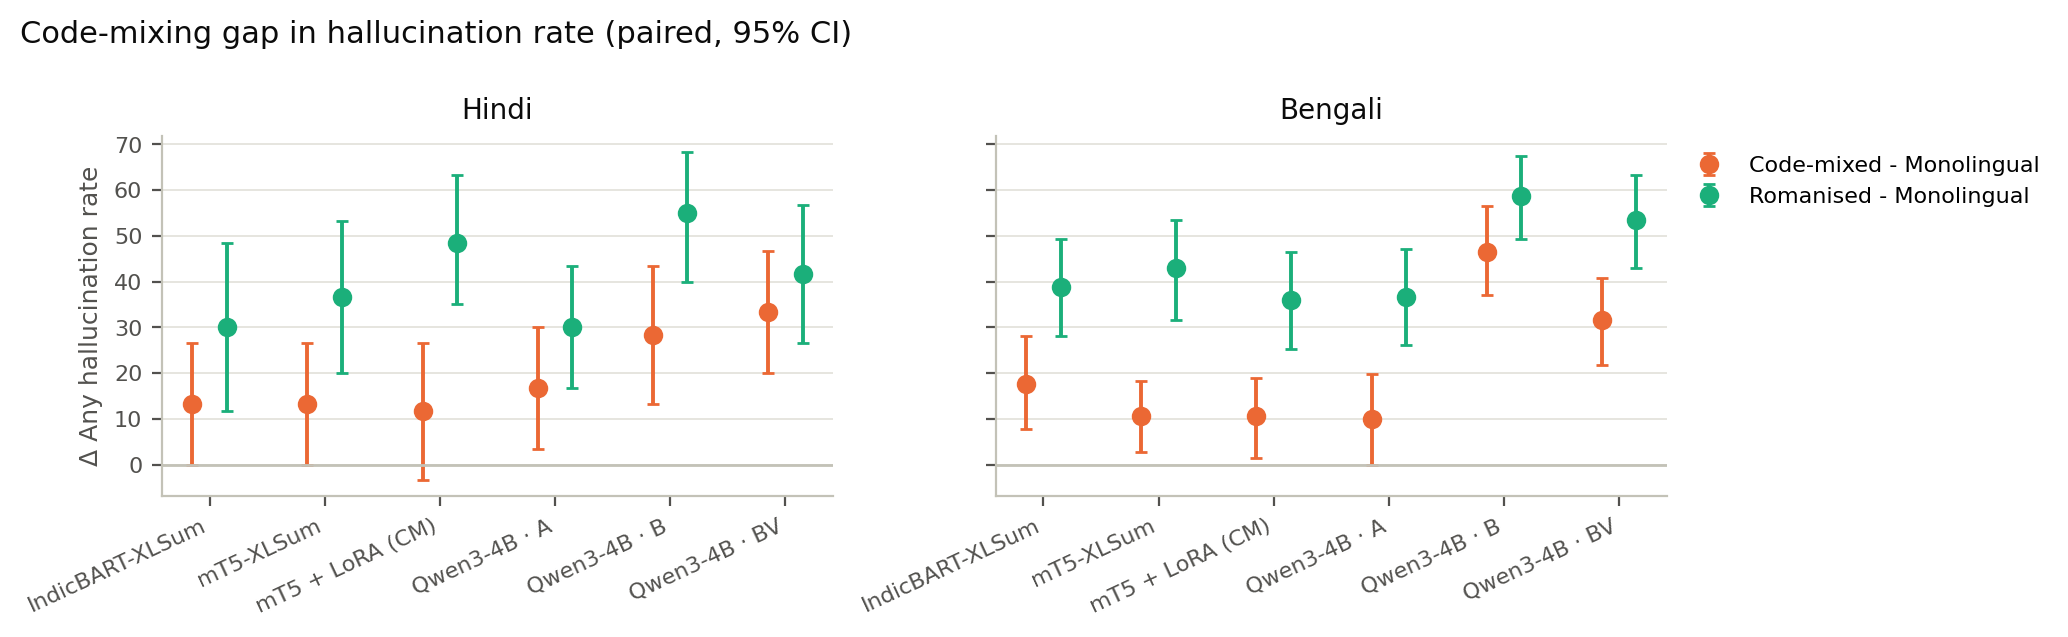

codemix_gap_nli.png


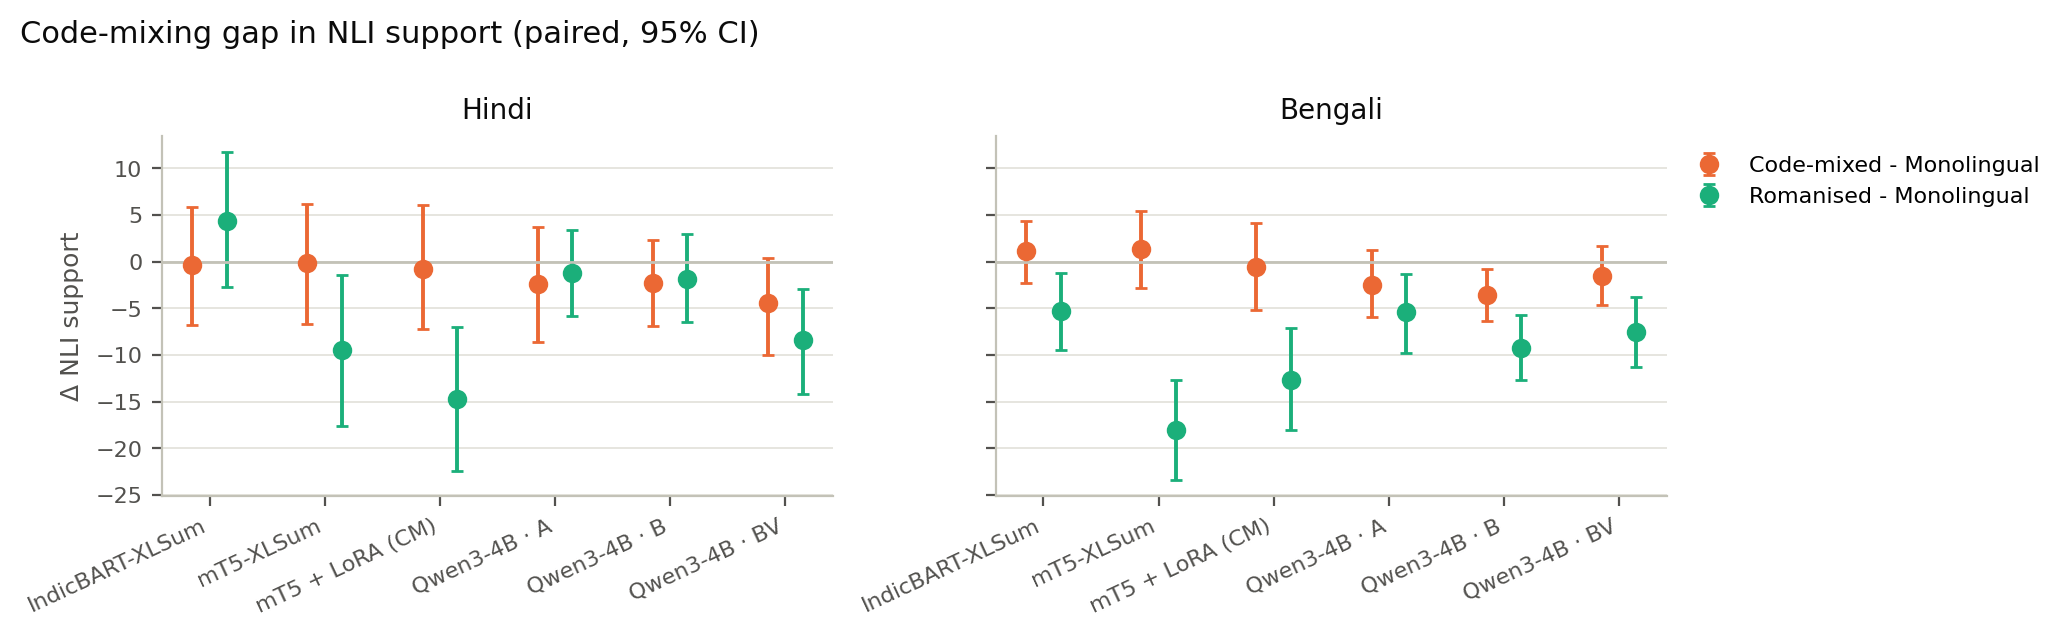

error_types.png


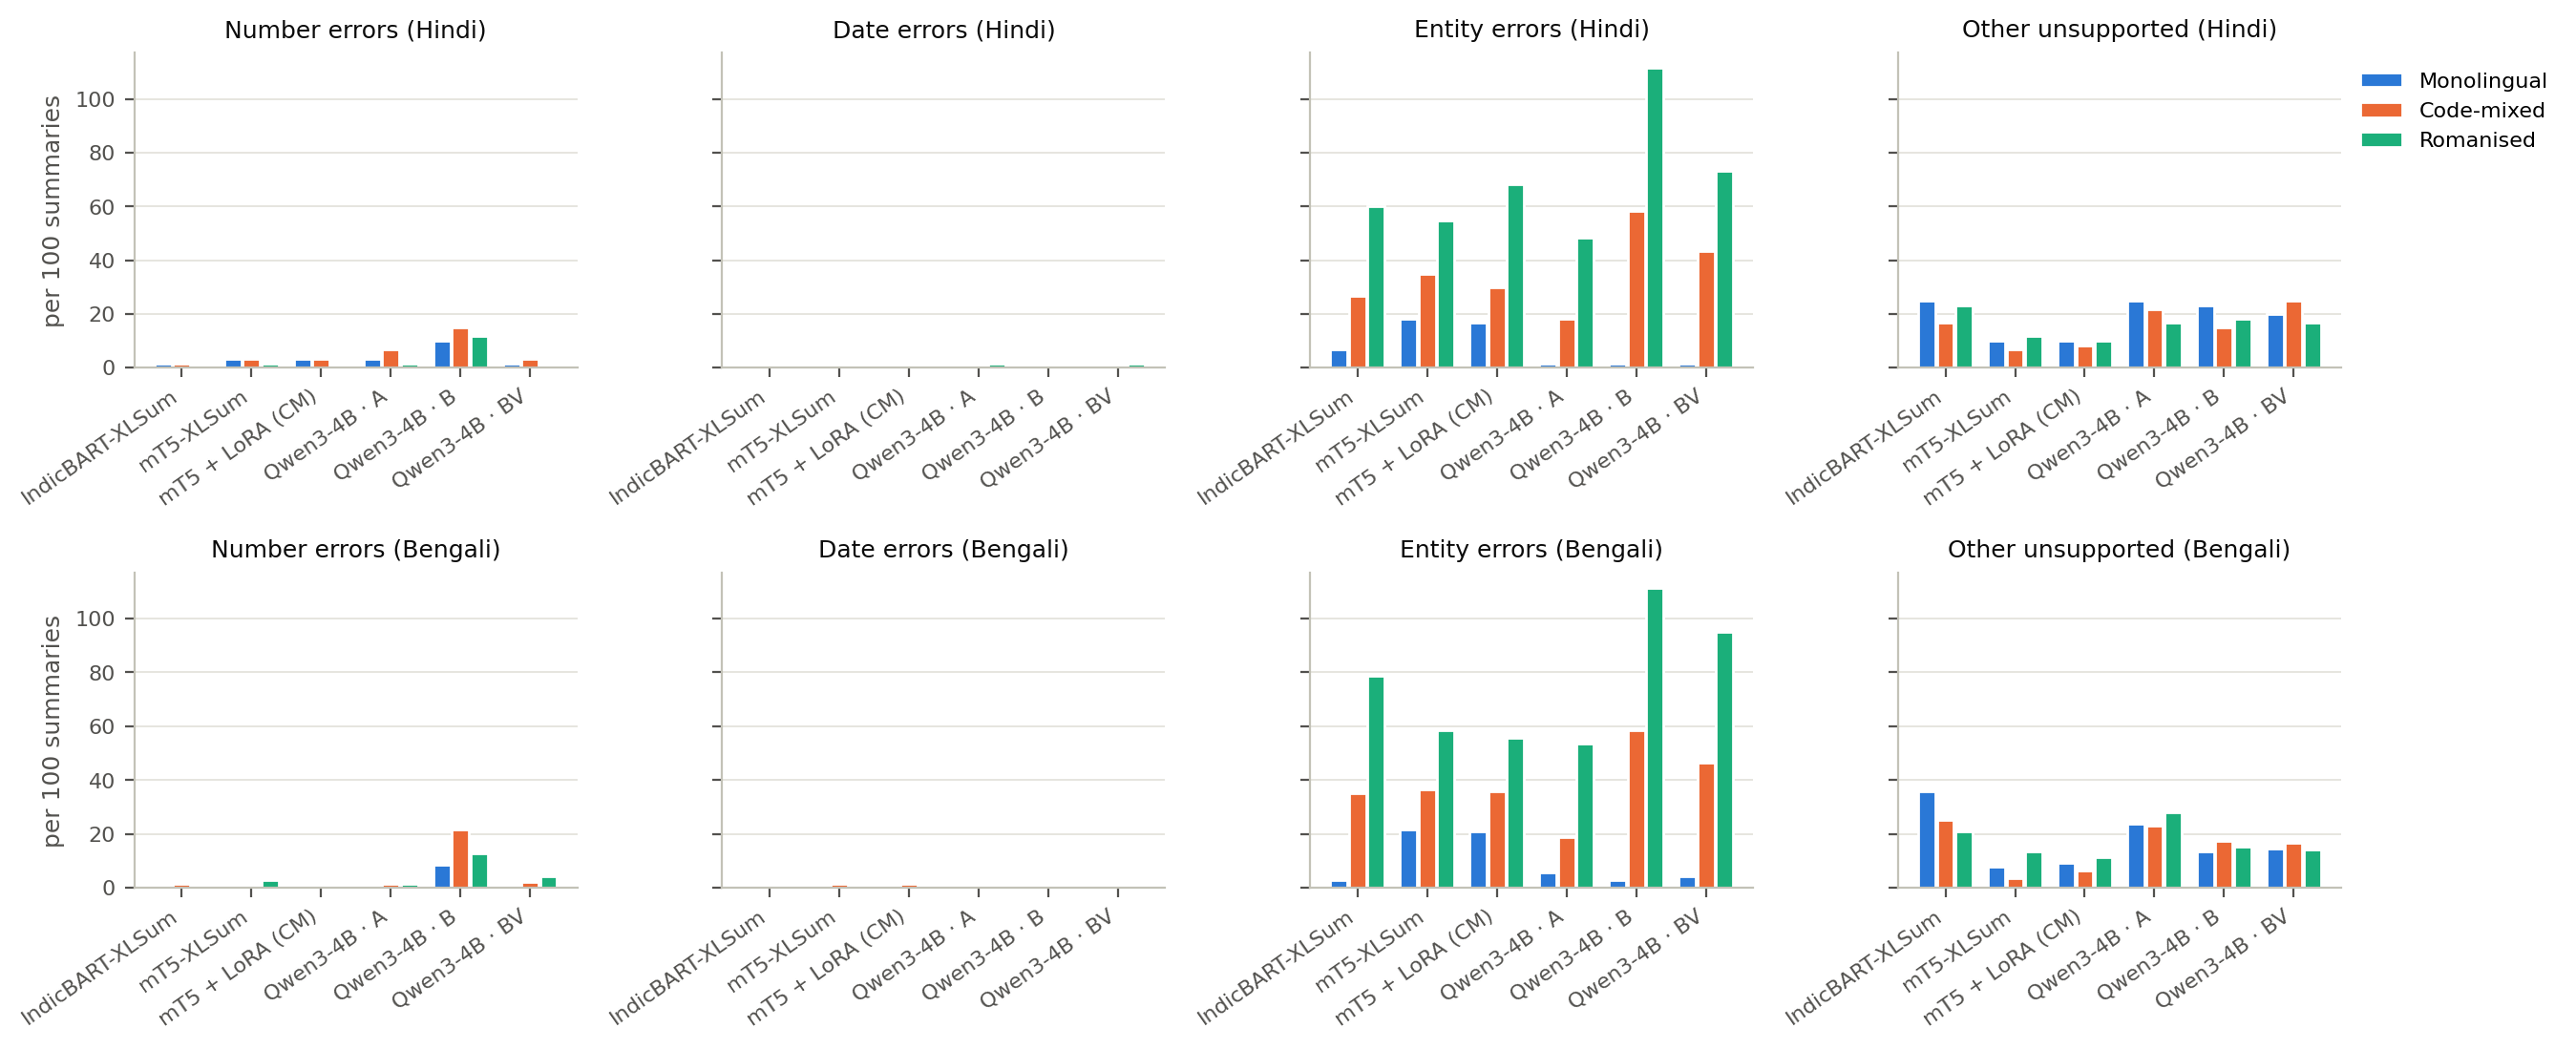

hallucination_rate_by_input.png


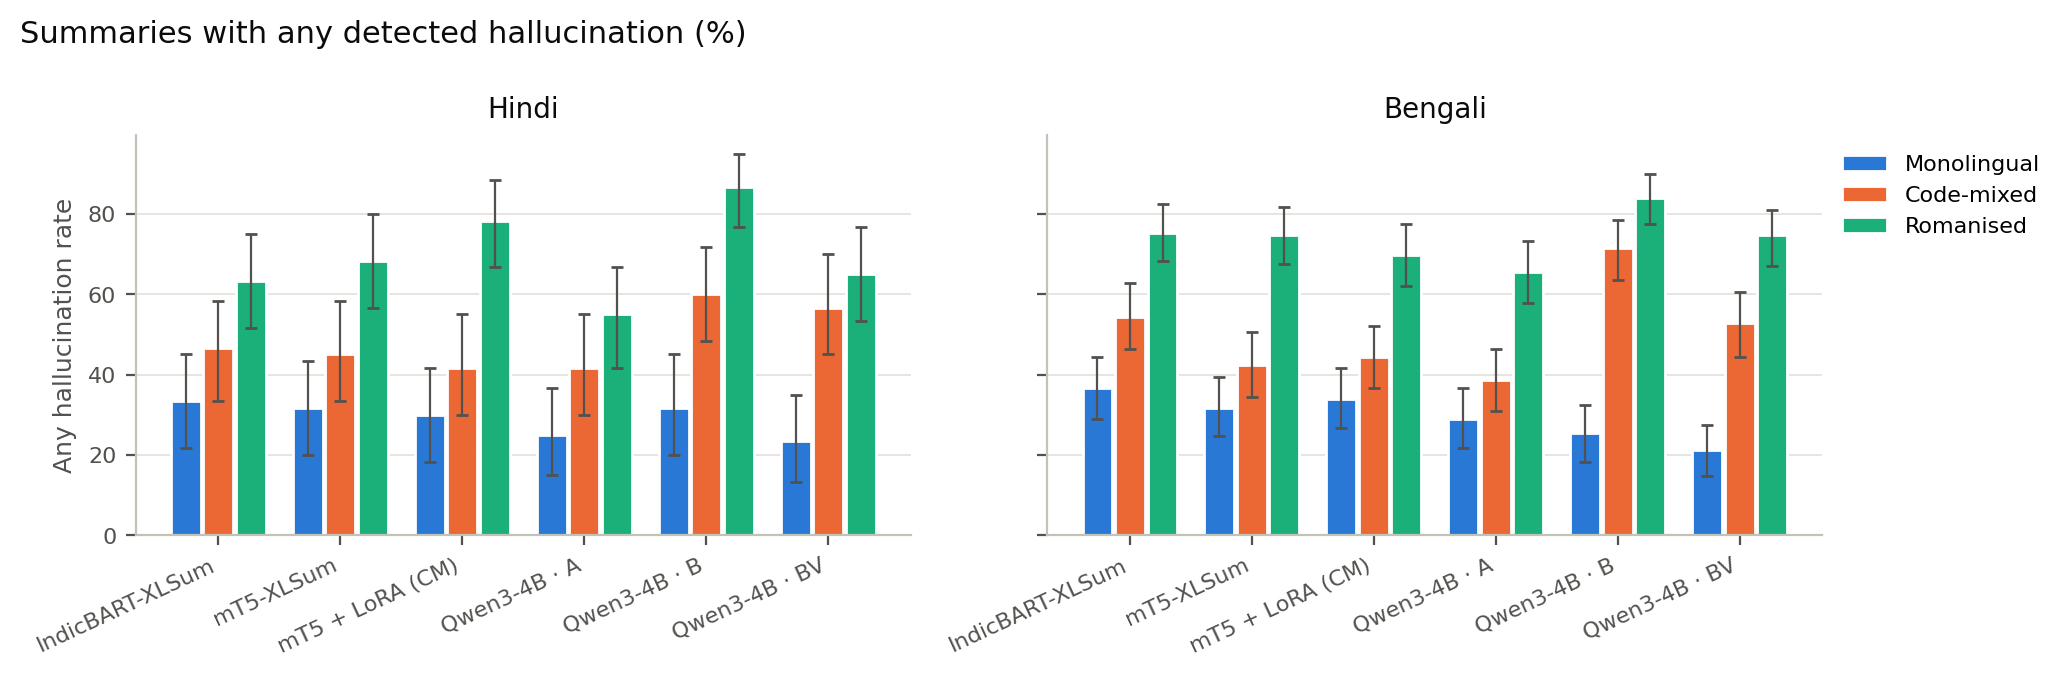

nli_by_cmi.png


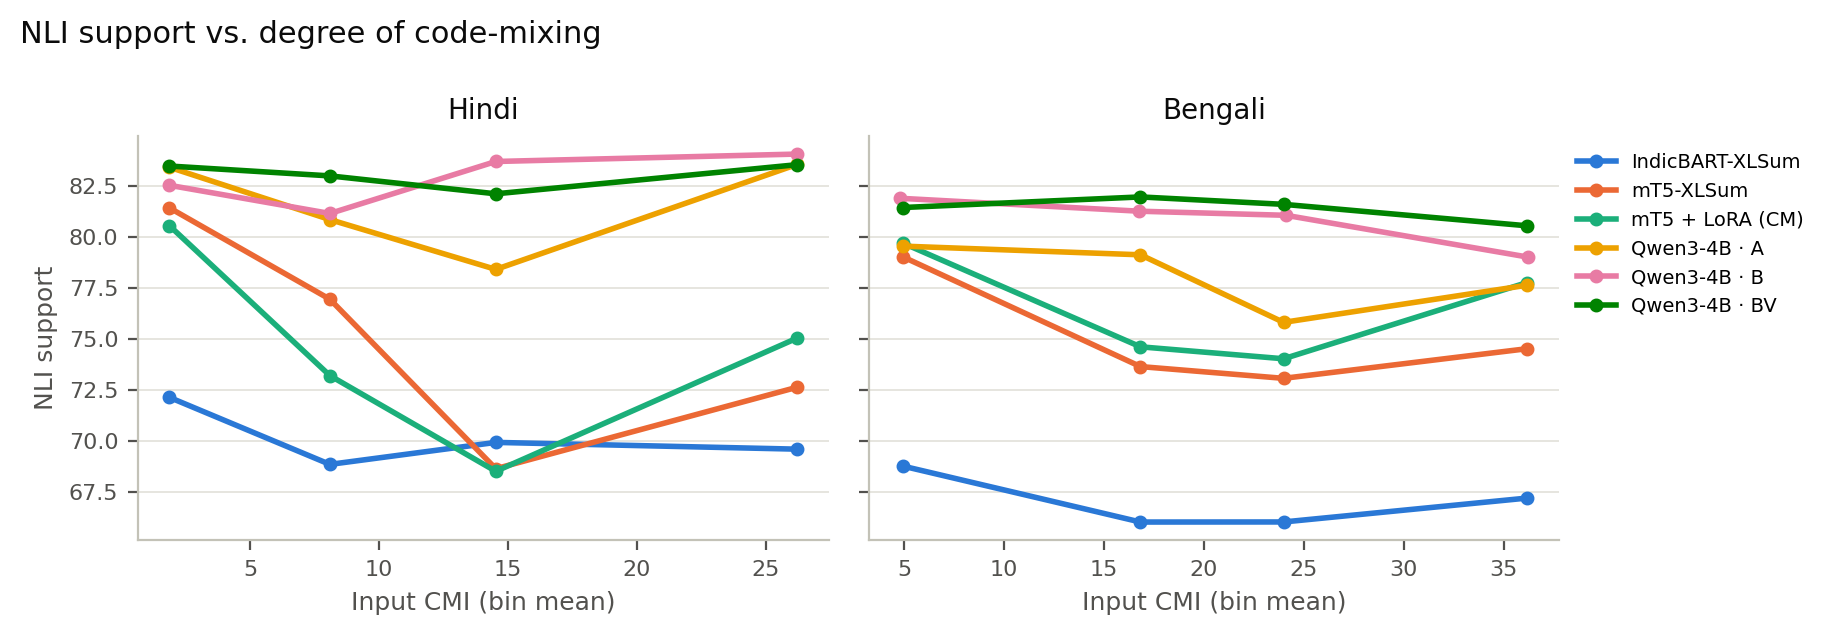

nli_support_by_input.png


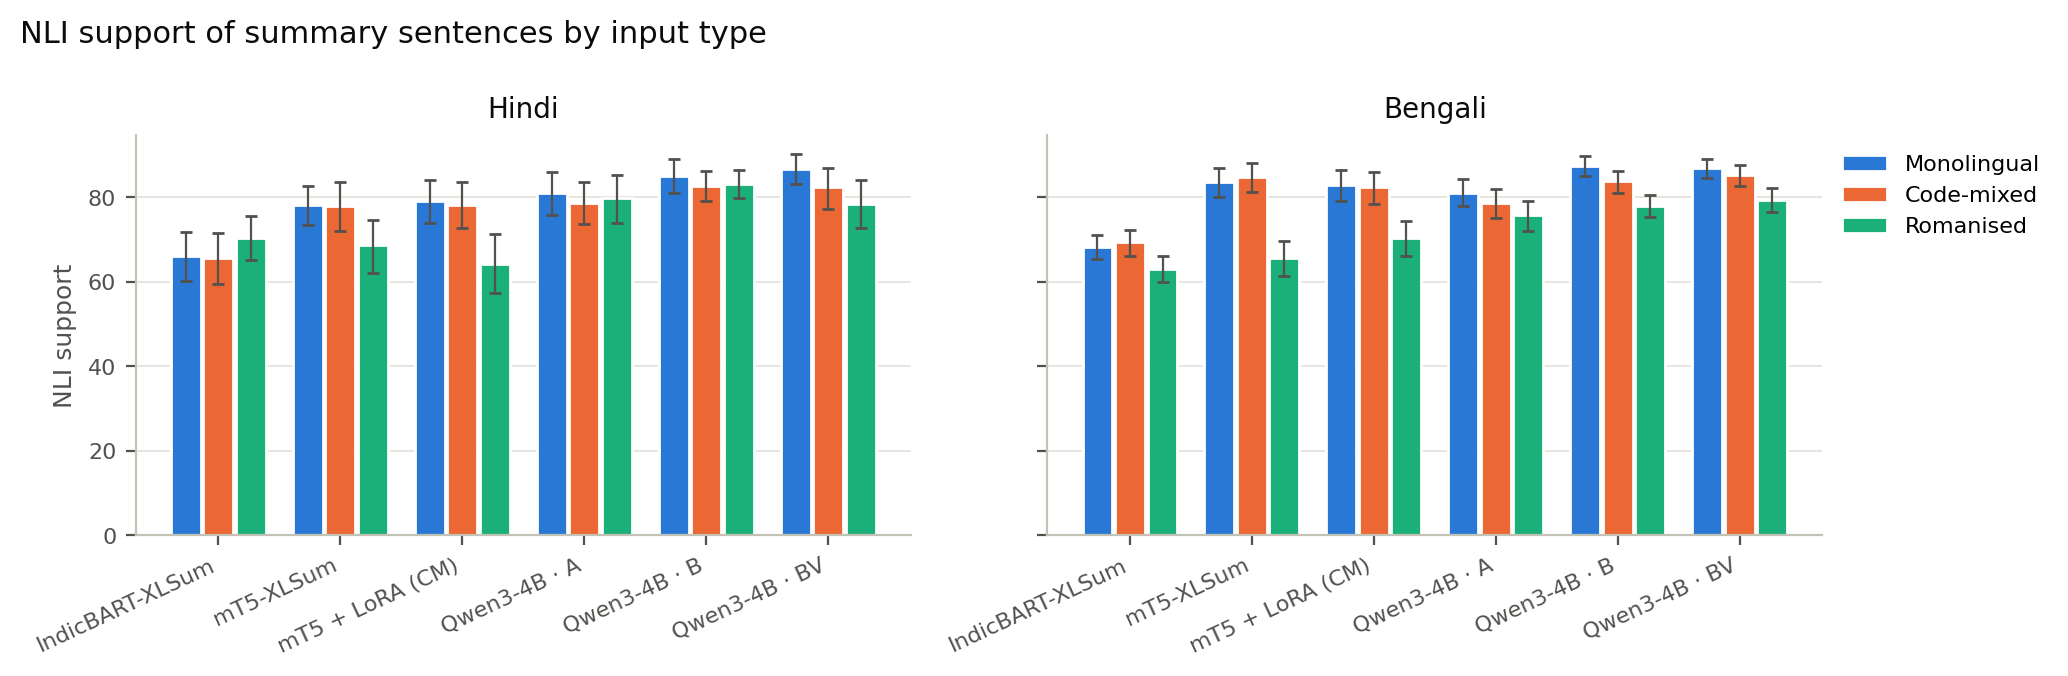

rougeL_by_input.png


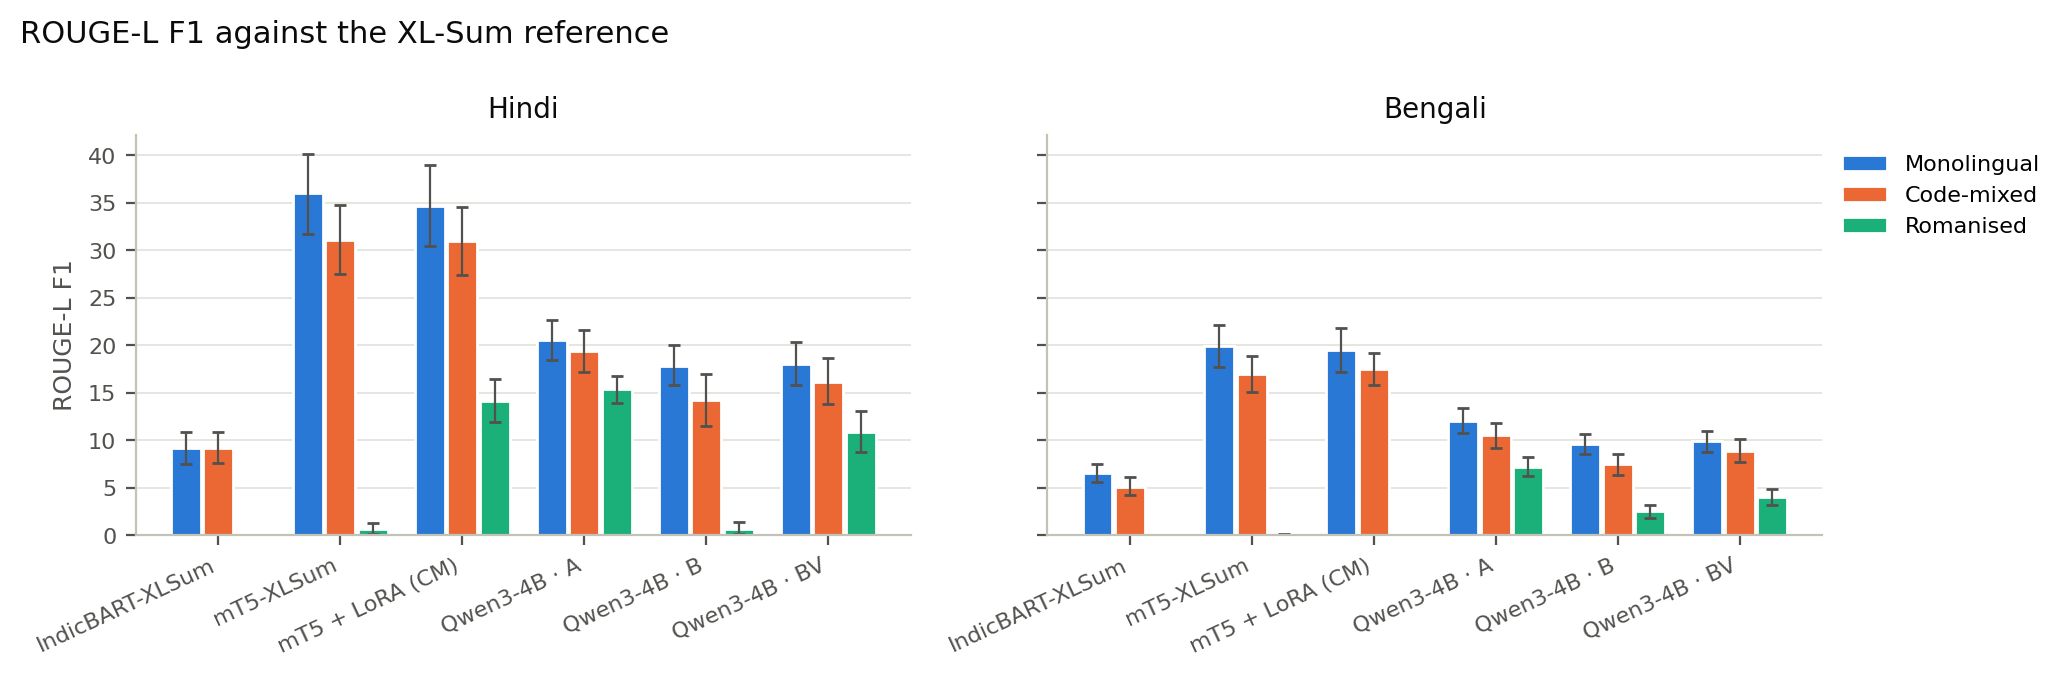

time_vs_factuality.png


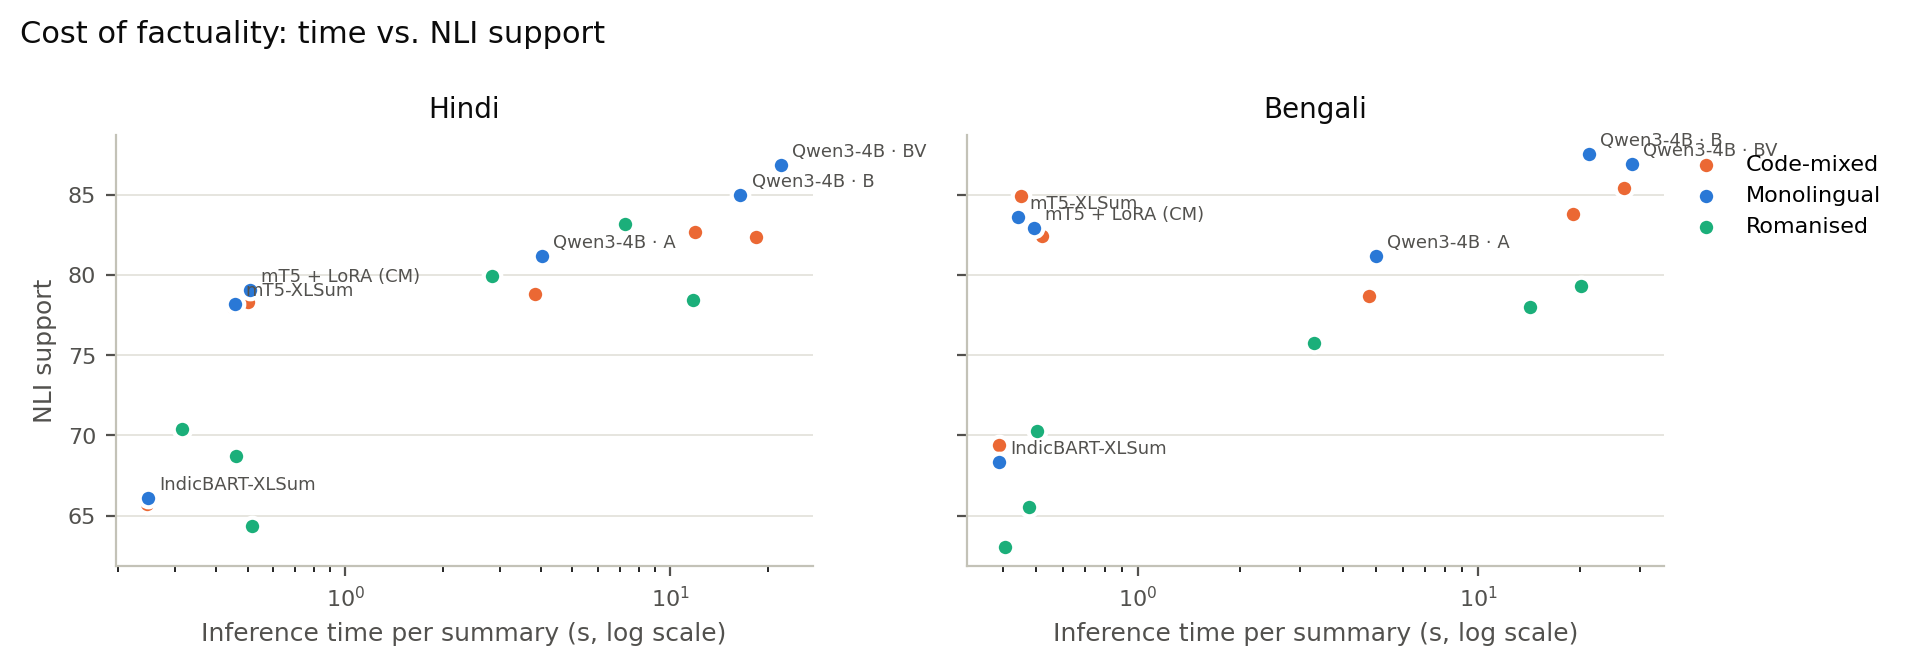

tokenizer_fertility.png


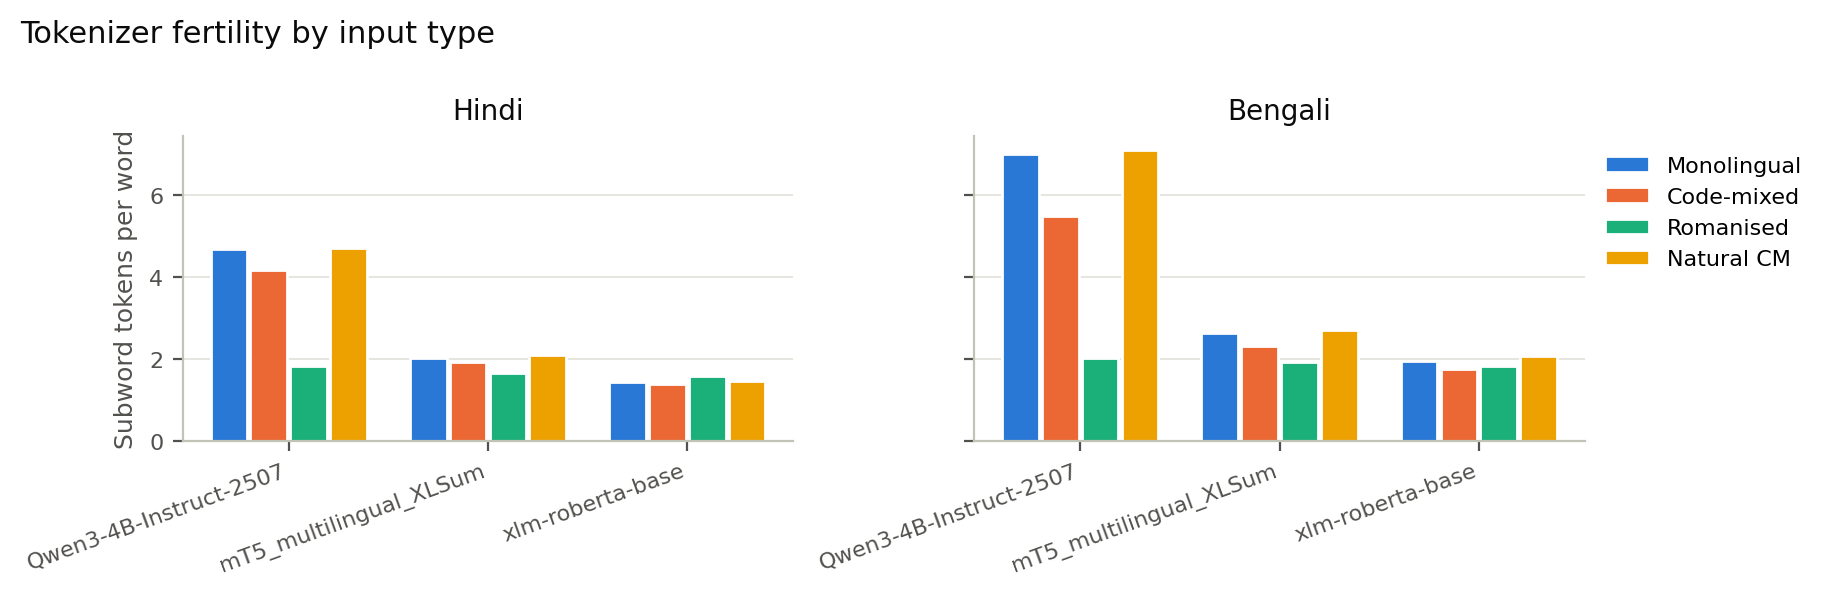

In [6]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob(f"{cfg.out_root}/06_evaluate/figures/*.png")):
    print(os.path.basename(f)); display(Image(f))

**Paper draft.** The cell below writes the IEEE-style paper (Word) with your numbers, tables and figures filled in: `06_evaluate/FactIndic_paper_draft.docx`. Yellow `[Write: ...]` notes mark the sentences that interpret the results; write those yourselves. Notebook 07 rebuilds it with the human evaluation.

In [7]:
from factindic.paper import build_paper
print(build_paper(cfg.out_root, f"{cfg.out_root}/06_evaluate/FactIndic_paper_draft.docx"))

/kaggle/working/factindic_out/06_evaluate/FactIndic_paper_draft.docx


**Next:** download `06_evaluate/human_eval/` from this notebook's Output tab. Send each `human_eval_<lang>_annotator<k>.xlsx` to one annotator, and keep `human_eval_KEY_do_not_share.csv` to yourself. When the files come back filled in, upload them as a Kaggle dataset and run notebook 07.

In [8]:
import os
for root, dirs, files in os.walk(cfg.out_root):
    dirs[:] = [d for d in dirs if not d.startswith("_")]
    depth = root[len(cfg.out_root):].count(os.sep)
    if depth <= 1:
        print("  " * depth + os.path.basename(root) + "/", ", ".join(sorted(files))[:300])

factindic_out/ 
  06_evaluate/ FactIndic_paper_draft.docx, config.json, examples.json, results.md, results_all.csv, results_all.jsonl, summary.md
  02_codemix/ codemix_quality_check.xlsx, codemix_report.md, config.json, env.json, variants.jsonl
  04_llm/ config.json, env.json, llm_report.md, qg.jsonl, summaries_llm.jsonl
  03_seq2seq/ config.json, lora_training.json, summaries_seq2seq.jsonl
  05_verify/ config.json, verification.jsonl, verify_report.md
  01_data/ config.json, data_report.md, data_stats.csv, docs.jsonl
